# Training pipeline: car insurance claim risk

This notebook is the training stage of Assignment 1. `uv run python main.py train`
converts it to a plain script and runs it top to bottom, so every cell must run
without manual steps.

1. Setup and decision constants
2. Load and check the data
3. Split into train / validation / test
4. Explore the training set
5. Feature engineering
6. Logistic regression, three ways
7. Threshold, calibration and the test set
8. Legal vs. illegal models: what the ban costs, and who gets declined
9. Saved artifacts for the app

In [1]:
import matplotlib
import numpy as np
import pandas as pd
from pathlib import Path

# main.py runs this notebook as a plain script. Outside Jupyter, switch to a
# non-interactive backend so a plot never opens a window and blocks the run.
try:
    get_ipython  # only defined inside Jupyter / IPython
    IN_NOTEBOOK = True
except NameError:
    IN_NOTEBOOK = False
    matplotlib.use("Agg")

import matplotlib.pyplot as plt


def show():
    """plt.show() inside Jupyter; just close the figure when run as a script."""
    if IN_NOTEBOOK:
        plt.show()
    else:
        plt.close("all")


# Chart style: fixed categorical colour order, light grid, no top/right frame
plt.rcParams.update({
    "axes.prop_cycle": matplotlib.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                                "#e87ba4", "#008300", "#6250d6", "#e34948"]),
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "legend.frameon": False,
})

SEED = 42
DATA_PATH = Path("data/Car_Insurance_Claim.csv")

pd.set_option("display.width", 120)
print("running in Jupyter:", IN_NOTEBOOK)

running in Jupyter: True


## 1. The decision and its costs

A car insurer receives an application and either **accepts it at the standard
premium** or **declines it**. The model estimates the probability that the applicant
makes a claim (`OUTCOME = 1`), and the applicant is declined when that probability is
above a threshold.

| | Applicant claims (1) | Applicant does not claim (0) |
|---|---|---|
| **Decline** (predict 1) | TP: €0, policy not written | FP: €0, but a profitable customer is lost |
| **Accept** (predict 0) | FN: premium − expenses − claim cost | TN: premium − expenses |

Cost inputs, Italian motor third-party liability market, 2025:

- Average cost of a claim: **€5,795**. ANIA, *L'Assicurazione italiana 2025–2026*, p. 17.
- Expense ratio: **20.5%** of premiums. Same report, p. 213.
- Current-year loss ratio: **79.8%** of premiums. Same report, p. 213.

**Standard premium.** Set so that the average applicant in the training set breaks
even at that loss ratio (computed in section 3, after the split). The real Italian
average premium (€421.5, IVASS IPER, Q2 2026) is not used directly: this dataset's
claim rate (~31%) is about 6.5× the Italian market's 4.84%, so at €421.5 almost every
applicant would be unprofitable.

**Assumption.** Italian law (art. 132 of the Codice delle Assicurazioni Private)
obliges insurers to accept compulsory motor-liability applicants. Here we assume
declining at standard terms is allowed.

In [2]:
# Cost inputs (Italy, motor third-party liability, 2025). Sources in the cell above.
AVG_CLAIM_COST = 5795.0    # EUR per claim, ANIA 2025-2026 p.17
EXPENSE_RATIO = 0.205      # expenses / premiums, ANIA 2025-2026 p.213
TARGET_LOSS_RATIO = 0.798  # current-year claims / premiums, ANIA 2025-2026 p.213

## 2. Load and check the data

One row is one policyholder. `OUTCOME = 1` means they made a claim. `ID` only
identifies the row and is never used as a feature.

In [3]:
df = pd.read_csv(DATA_PATH)

print("shape:", df.shape)
print("duplicate IDs:", df["ID"].duplicated().sum())
print("\nmissing values:")
print(df.isna().sum()[lambda s: s > 0])
print("\nclaim rate:", round(df["OUTCOME"].mean(), 3))
df.head()

shape: (10000, 19)
duplicate IDs: 0

missing values:
CREDIT_SCORE      982
ANNUAL_MILEAGE    957
dtype: int64

claim rate: 0.313


,ID,AGE,GENDER,RACE,DRIVING_EXPERIENCE,EDUCATION,INCOME,CREDIT_SCORE,VEHICLE_OWNERSHIP,VEHICLE_YEAR,MARRIED,CHILDREN,POSTAL_CODE,ANNUAL_MILEAGE,VEHICLE_TYPE,SPEEDING_VIOLATIONS,DUIS,PAST_ACCIDENTS,OUTCOME
0,569520,65+,female,majority,0-9y,high school,upper class,0.629027,1.0,after 2015,0.0,1.0,10238,12000.0,sedan,0,0,0,0.0
1,750365,16-25,male,majority,0-9y,none,poverty,0.357757,0.0,before 2015,0.0,0.0,10238,16000.0,sedan,0,0,0,1.0
2,199901,16-25,female,majority,0-9y,high school,working class,0.493146,1.0,before 2015,0.0,0.0,10238,11000.0,sedan,0,0,0,0.0
3,478866,16-25,male,majority,0-9y,university,working class,0.206013,1.0,before 2015,0.0,1.0,32765,11000.0,sedan,0,0,0,0.0
4,731664,26-39,male,majority,10-19y,none,working class,0.388366,1.0,before 2015,0.0,0.0,32765,12000.0,sedan,2,0,1,1.0


In [4]:
# Binary columns are stored as floats (0.0 / 1.0); make them integers.
for col in ["VEHICLE_OWNERSHIP", "MARRIED", "CHILDREN", "OUTCOME"]:
    df[col] = df[col].astype(int)

# Levels of every categorical column (POSTAL_CODE is a label, not a number)
for col in ["AGE", "GENDER", "RACE", "DRIVING_EXPERIENCE", "EDUCATION", "INCOME",
            "VEHICLE_YEAR", "VEHICLE_TYPE", "POSTAL_CODE"]:
    print(f"{col:20s}", sorted(df[col].unique().tolist(), key=str))

AGE                  ['16-25', '26-39', '40-64', '65+']
GENDER               ['female', 'male']
RACE                 ['majority', 'minority']
DRIVING_EXPERIENCE   ['0-9y', '10-19y', '20-29y', '30y+']
EDUCATION            ['high school', 'none', 'university']
INCOME               ['middle class', 'poverty', 'upper class', 'working class']
VEHICLE_YEAR         ['after 2015', 'before 2015']
VEHICLE_TYPE         ['sedan', 'sports car']
POSTAL_CODE          [10238, 21217, 32765, 92101]


## 3. Split: train / validation / test

- **Random, not time-based.** The data has no dates, so applicants cannot be ordered
  in time. This is a limitation: a real insurer would train on past years and test on
  the most recent one.
- **Stratified on `OUTCOME`**, so all three sets have the same claim rate.
- **60 / 20 / 20.** Train fits the models. Validation chooses the regularisation
  strength and checks calibration and the threshold (the learning rates are chosen on
  training loss, see section 6). Test is used once, at the end.
- From here on, everything learned from data (exploration, fill-in values for missing
  data, scaling) comes from the **training set only**.

In [5]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df, test_size=0.4, stratify=df["OUTCOME"], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.5, stratify=temp_df["OUTCOME"], random_state=SEED
)

for name, part in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    print(f"{name:10s} rows={len(part):5d}  claim rate={part['OUTCOME'].mean():.3f}")

train      rows= 6000  claim rate=0.313
validation rows= 2000  claim rate=0.314
test       rows= 2000  claim rate=0.313


In [6]:
# Standard premium: the average training applicant breaks even at the market loss ratio.
train_claim_rate = train_df["OUTCOME"].mean()
STANDARD_PREMIUM = train_claim_rate * AVG_CLAIM_COST / TARGET_LOSS_RATIO
margin = STANDARD_PREMIUM * (1 - EXPENSE_RATIO)  # premium left after expenses

# Value of each outcome per applicant, in EUR (same notation as the calibration lab)
V_TP = 0.0                     # declined, would have claimed: policy not written
V_FP = 0.0                     # declined, would not have claimed: policy not written
V_TN = margin                  # accepted, no claim
V_FN = margin - AVG_CLAIM_COST # accepted, claims

T_STAR = (V_TN - V_FP) / ((V_TN - V_FP) + (V_TP - V_FN))

print(f"training claim rate: {train_claim_rate:.3f}")
print(f"standard premium:    EUR {STANDARD_PREMIUM:,.0f}")
print(f"V_TN = {V_TN:,.0f}   V_FN = {V_FN:,.0f}   V_TP = {V_TP:,.0f}   V_FP = {V_FP:,.0f}")
print(f"cost-based threshold t* = {T_STAR:.3f}")

training claim rate: 0.313
standard premium:    EUR 2,275
V_TN = 1,809   V_FN = -3,986   V_TP = 0   V_FP = 0
cost-based threshold t* = 0.312


## 4. Exploring the training set

Only `train_df` is used in this section.

### 4.1 Claim rate by category

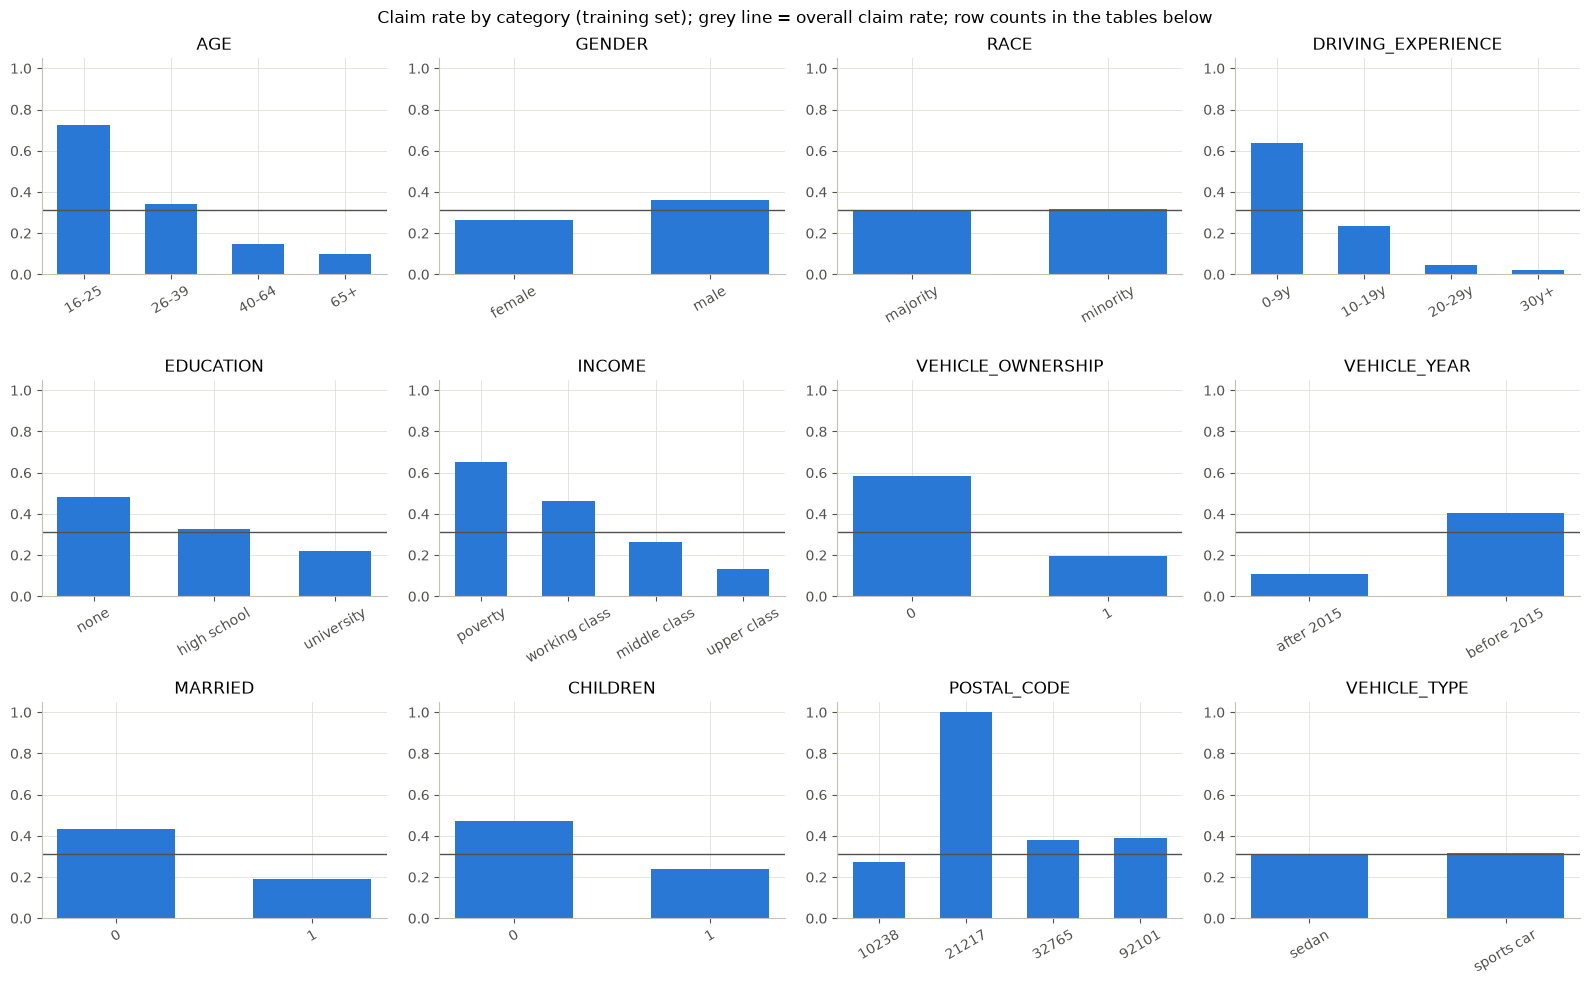

AGE            16-25    26-39     40-64       65+
claim_rate     0.727     0.34     0.149     0.098
n           1182.000  1904.00  1730.000  1184.000 

GENDER        female      male
claim_rate     0.264     0.363
n           3014.000  2986.000 

RACE        majority  minority
claim_rate     0.313     0.315
n           5391.000   609.000 

DRIVING_EXPERIENCE      0-9y    10-19y    20-29y     30y+
claim_rate             0.638     0.237     0.047    0.019
n                   2080.000  2040.000  1258.000  622.000 

EDUCATION      none  high school  university
claim_rate     0.48        0.325       0.219
n           1159.00     2499.000    2342.000 

INCOME       poverty  working class  middle class  upper class
claim_rate     0.654          0.463         0.265        0.131
n           1093.000       1066.000      1251.000     2590.000 

VEHICLE_OWNERSHIP         0         1
claim_rate            0.582     0.197
n                  1815.000  4185.000 

VEHICLE_YEAR  after 2015  before 2015


In [7]:
eda = train_df.copy()

CAT_COLS = ["AGE", "GENDER", "RACE", "DRIVING_EXPERIENCE", "EDUCATION", "INCOME",
            "VEHICLE_OWNERSHIP", "VEHICLE_YEAR", "MARRIED", "CHILDREN",
            "POSTAL_CODE", "VEHICLE_TYPE"]
ORDER = {  # natural order of the banded columns
    "AGE": ["16-25", "26-39", "40-64", "65+"],
    "DRIVING_EXPERIENCE": ["0-9y", "10-19y", "20-29y", "30y+"],
    "EDUCATION": ["none", "high school", "university"],
    "INCOME": ["poverty", "working class", "middle class", "upper class"],
}


def claim_rate_by(col):
    table = eda.groupby(col)["OUTCOME"].agg(claim_rate="mean", n="size")
    return table.loc[ORDER[col]] if col in ORDER else table


fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.ravel(), CAT_COLS):
    table = claim_rate_by(col)
    ax.bar(table.index.astype(str), table["claim_rate"], width=0.6)
    ax.axhline(train_claim_rate, color="#52514e", lw=1)
    ax.set(title=col, ylim=(0, 1.05))
    ax.tick_params(axis="x", rotation=30)
fig.suptitle("Claim rate by category (training set); grey line = overall claim rate; row counts in the tables below")
fig.tight_layout()
show()

for col in CAT_COLS:
    print(claim_rate_by(col).round(3).T.to_string(), "\n")

### 4.2 Numeric columns

                      count      mean      std      min       25%       50%       75%       max
CREDIT_SCORE         5400.0      0.51     0.14     0.06      0.41      0.52      0.62      0.92
ANNUAL_MILEAGE       5432.0  11729.93  2846.56  2000.00  10000.00  12000.00  14000.00  22000.00
SPEEDING_VIOLATIONS  6000.0      1.47     2.23     0.00      0.00      0.00      2.00     22.00
DUIS                 6000.0      0.25     0.57     0.00      0.00      0.00      0.00      5.00
PAST_ACCIDENTS       6000.0      1.06     1.65     0.00      0.00      0.00      2.00     15.00


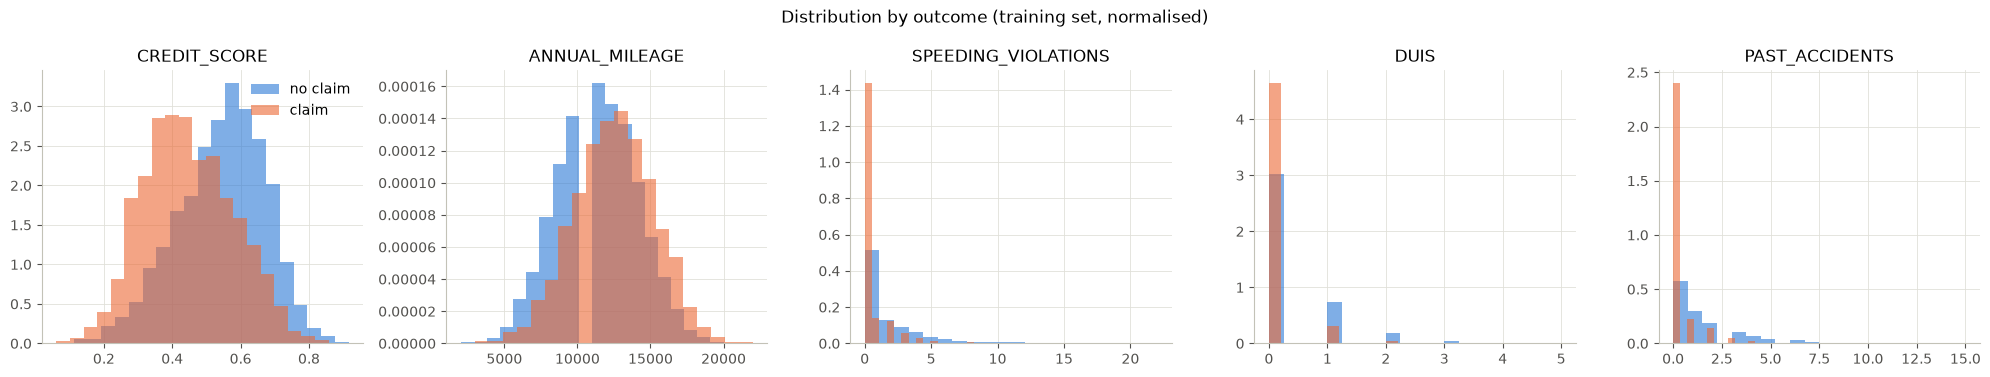

In [8]:
NUM_COLS = ["CREDIT_SCORE", "ANNUAL_MILEAGE", "SPEEDING_VIOLATIONS", "DUIS", "PAST_ACCIDENTS"]
print(eda[NUM_COLS].describe().round(2).T)

fig, axes = plt.subplots(1, 5, figsize=(20, 3.8))
for ax, col in zip(axes, NUM_COLS):
    for outcome, label in [(0, "no claim"), (1, "claim")]:
        values = eda.loc[eda["OUTCOME"] == outcome, col].dropna()
        ax.hist(values, bins=20, alpha=0.6, density=True, label=label)
    ax.set_title(col)
axes[0].legend()
fig.suptitle("Distribution by outcome (training set, normalised)")
fig.tight_layout()
show()

In [9]:
# The three count columns have long tails: claim rate and row count per value
for col in ["SPEEDING_VIOLATIONS", "DUIS", "PAST_ACCIDENTS"]:
    print(eda.groupby(col)["OUTCOME"].agg(claim_rate="mean", n="size").round(3).T.to_string(), "\n")

SPEEDING_VIOLATIONS        0        1        2        3        4        5        6       7       8       9       10    11    12   13   14   15   17   18   19   22
claim_rate              0.494    0.151    0.176    0.121    0.106    0.076    0.029   0.053   0.125   0.061   0.071   0.1   0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
n                    3009.000  951.000  723.000  479.000  311.000  185.000  105.000  75.000  48.000  33.000  28.000  20.0  12.0  8.0  2.0  6.0  2.0  1.0  1.0  1.0 

DUIS               0        1        2      3      4    5
claim_rate     0.359    0.131    0.078   0.02  0.286  0.0
n           4862.000  873.000  206.000  50.00  7.000  2.0 

PAST_ACCIDENTS        0         1        2        3        4        5       6       7     8     9    10   11   12   15
claim_rate         0.471     0.141    0.137    0.086    0.072    0.037   0.033   0.057   0.0   0.0  0.0  0.0  0.0  0.0
n               3357.000  1058.000  681.000  360.000  235.000  136.000  92.000  35.000  22.0  1

### 4.3 Missing values

Two questions: is *being missing* itself related to claiming, and which other columns
could help fill in a missing value?

In [10]:
for col in ["CREDIT_SCORE", "ANNUAL_MILEAGE"]:
    missing = eda[col].isna()
    print(f"{col}: {missing.mean():.1%} missing | claim rate when missing "
          f"{eda.loc[missing, 'OUTCOME'].mean():.3f} vs present {eda.loc[~missing, 'OUTCOME'].mean():.3f}")

print("\nmedian CREDIT_SCORE by group:")
for col in ["INCOME", "EDUCATION", "AGE"]:
    print(eda.groupby(col)["CREDIT_SCORE"].median().loc[ORDER[col]].round(3).to_dict())

print("\nmedian ANNUAL_MILEAGE by group:")
for col in ["MARRIED", "CHILDREN", "AGE"]:
    medians = eda.groupby(col)["ANNUAL_MILEAGE"].median()
    print(col, (medians.loc[ORDER[col]] if col in ORDER else medians).to_dict())

CREDIT_SCORE: 10.0% missing | claim rate when missing 0.288 vs present 0.316
ANNUAL_MILEAGE: 9.5% missing | claim rate when missing 0.324 vs present 0.312

median CREDIT_SCORE by group:
{'poverty': 0.349, 'working class': 0.429, 'middle class': 0.527, 'upper class': 0.616}
{'none': 0.401, 'high school': 0.513, 'university': 0.58}
{'16-25': 0.398, '26-39': 0.487, '40-64': 0.566, '65+': 0.611}

median ANNUAL_MILEAGE by group:
MARRIED {0: 13000.0, 1: 10000.0}
CHILDREN {0: 14000.0, 1: 11000.0}
AGE {'16-25': 13000.0, '26-39': 12000.0, '40-64': 11000.0, '65+': 11000.0}


### 4.4 Consistency between age and driving experience

In [11]:
pd.crosstab(eda["AGE"], eda["DRIVING_EXPERIENCE"]).loc[ORDER["AGE"], ORDER["DRIVING_EXPERIENCE"]]

DRIVING_EXPERIENCE,0-9y,10-19y,20-29y,30y+
AGE,,,,
16-25,1182,0,0,0
26-39,429,1475,0,0
40-64,299,347,1084,0
65+,170,218,174,622


### 4.5 Count columns and driving experience

The count columns are compared with driving experience, then claim rates for 0 vs 1+
are compared within each experience band.

In [12]:
COUNT_COLS = ["SPEEDING_VIOLATIONS", "DUIS", "PAST_ACCIDENTS"]
exp_order = ORDER["DRIVING_EXPERIENCE"]

print("claim rate and mean counts by driving experience:")
print(eda.groupby("DRIVING_EXPERIENCE")[["OUTCOME"] + COUNT_COLS].mean().loc[exp_order].round(2))

for col in ["SPEEDING_VIOLATIONS", "PAST_ACCIDENTS"]:
    any_count = np.where(eda[col] > 0, "1+", "0")
    table = eda.pivot_table(index="DRIVING_EXPERIENCE", columns=any_count, values="OUTCOME",
                            aggfunc=["mean", "size"]).loc[exp_order]
    print(f"\nclaim rate by {col} (0 vs 1+) within each experience band:")
    print(table.round(3))

claim rate and mean counts by driving experience:
                    OUTCOME  SPEEDING_VIOLATIONS  DUIS  PAST_ACCIDENTS
DRIVING_EXPERIENCE                                                    
0-9y                   0.64                 0.00  0.00            0.00
10-19y                 0.24                 1.27  0.22            0.96
20-29y                 0.05                 2.76  0.49            1.95
30y+                   0.02                 4.40  0.66            3.10

claim rate by SPEEDING_VIOLATIONS (0 vs 1+) within each experience band:
                     mean           size        
                        0     1+       0      1+
DRIVING_EXPERIENCE                              
0-9y                0.638    NaN  2080.0     NaN
10-19y              0.201  0.256   717.0  1323.0
20-29y              0.068  0.043   177.0  1081.0
30y+                0.086  0.015    35.0   587.0

claim rate by PAST_ACCIDENTS (0 vs 1+) within each experience band:
                     mean           si

### 4.6 Gender and race

How strongly each protected attribute is related to the other columns (Cramér's V:
0 = unrelated, 1 = one determines the other) and to the outcome. This is the first
look at whether the legal columns could stand in for the banned ones.

In [13]:
from scipy.stats import chi2_contingency


def cramers_v(a, b):
    table = pd.crosstab(a, b)
    chi2 = chi2_contingency(table)[0]
    return np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))


others = [c for c in CAT_COLS if c not in ("GENDER", "RACE")] + ["OUTCOME"]
association = pd.DataFrame(
    {attr: [cramers_v(eda[attr], eda[col]) for col in others] for attr in ["GENDER", "RACE"]},
    index=others,
).round(3)
print(association.sort_values("GENDER", ascending=False))

print("\nmean of the count columns by gender:")
print(eda.groupby("GENDER")[["SPEEDING_VIOLATIONS", "DUIS", "PAST_ACCIDENTS"]].mean().round(2))
print("\nmean CREDIT_SCORE by race:", eda.groupby("RACE")["CREDIT_SCORE"].mean().round(3).to_dict())

                    GENDER   RACE
OUTCOME              0.106  0.001
EDUCATION            0.082  0.133
CHILDREN             0.021  0.009
INCOME               0.020  0.063
DRIVING_EXPERIENCE   0.019  0.034
AGE                  0.016  0.025
POSTAL_CODE          0.013  0.029
MARRIED              0.006  0.034
VEHICLE_OWNERSHIP    0.003  0.040
VEHICLE_YEAR         0.002  0.016
VEHICLE_TYPE         0.001  0.006

mean of the count columns by gender:
        SPEEDING_VIOLATIONS  DUIS  PAST_ACCIDENTS
GENDER                                           
female                 1.00  0.19            0.67
male                   1.94  0.31            1.45

mean CREDIT_SCORE by race: {'majority': 0.516, 'minority': 0.493}


## 5. Feature engineering

The code lives in `pipeline.py`, so the app transforms a new applicant in exactly the
same way. Each step, and the evidence from section 4 behind it:

| Step | Choice | Evidence |
|---|---|---|
| Banded columns (age, experience, education, income) | One-hot, first band as the reference | Claim rate does not fall in equal steps (experience: 64% → 24% → 5% → 2%), so each band gets its own coefficient |
| Speeding tickets, DUIs, past accidents | Capped at the training set's 99th percentile | Long tails (up to 22 tickets) with very few drivers at the top |
| Missing credit score (~10%) | Median of the applicant's income group | Credit score rises with income (median 0.35 → 0.62) |
| Missing annual mileage (~9.5%) | Median of the applicant's married × children group | Mileage is lower for married drivers and drivers with children |
| Missing-value flags | Not added | Claim rate is about the same whether the value is missing or not |
| Postal code | One-hot, including 21217 (every training row claimed) | Kept as observed; the L2 penalty in section 6 keeps its coefficient finite |
| All final columns | Standardised with the training mean and std | Gradient descent moves every weight at a similar speed, and the L2 penalty treats every column alike |

The main model is the **Legal** version: every column except gender and race.

In [14]:
from pipeline import (CATEGORIES, FEATURE_SETS, LogisticRegressionNet, Preprocessor, TARGET,
                      outcome_values, profit_per_applicant)

prep = Preprocessor(FEATURE_SETS["legal"]).fit(train_df)

print("caps (99th percentile):", prep.caps_)
print("credit score fill-in by income:", {k: round(v, 3) for k, v in prep.credit_by_income_.items()})
print("mileage fill-in by (married, children):", prep.mileage_by_family_)

X_train, X_val, X_test = (prep.transform(part) for part in (train_df, val_df, test_df))
y_train, y_val, y_test = (part[TARGET].to_numpy(np.float32) for part in (train_df, val_df, test_df))
assert not any(np.isnan(X).any() for X in (X_train, X_val, X_test))

print(f"\n{X_train.shape[1]} features:", prep.feature_names_)

caps (99th percentile): {'SPEEDING_VIOLATIONS': 10.0, 'DUIS': 2.0, 'PAST_ACCIDENTS': 7.0}
credit score fill-in by income: {'middle class': 0.527, 'poverty': 0.349, 'upper class': 0.616, 'working class': 0.429}
mileage fill-in by (married, children): {(0, 0): 14000.0, (0, 1): 12000.0, (1, 0): 12000.0, (1, 1): 10000.0}

24 features: ['AGE=26-39', 'AGE=40-64', 'AGE=65+', 'DRIVING_EXPERIENCE=10-19y', 'DRIVING_EXPERIENCE=20-29y', 'DRIVING_EXPERIENCE=30y+', 'EDUCATION=high school', 'EDUCATION=university', 'INCOME=working class', 'INCOME=middle class', 'INCOME=upper class', 'VEHICLE_YEAR=after 2015', 'VEHICLE_TYPE=sports car', 'POSTAL_CODE=21217', 'POSTAL_CODE=32765', 'POSTAL_CODE=92101', 'VEHICLE_OWNERSHIP', 'MARRIED', 'CHILDREN', 'SPEEDING_VIOLATIONS', 'DUIS', 'PAST_ACCIDENTS', 'CREDIT_SCORE', 'ANNUAL_MILEAGE']


## 6. Logistic regression, three ways (Legal version)

All three implementations minimise the **same objective**:

$$\text{loss}(w, b) = \frac{1}{n}\sum_{i=1}^{n} \text{BCE}\big(y_i,\ \sigma(x_i \cdot w + b)\big) + \frac{\lambda}{2}\lVert w \rVert^2, \qquad \lambda = \frac{1}{C\,n}$$

scikit-learn's `LogisticRegression` minimises $\tfrac12\lVert w\rVert^2 + C\sum_i \text{BCE}_i$.
Dividing that by $C\,n$ gives the line above, so both have the same minimum. The bias
$b$ is not penalised in any of the three. The objective is convex, so if all three
reach its minimum they must end up with the same coefficients.

What is tuned, and how:

- **C** (regularisation strength) is part of the model. It is chosen once, with
  scikit-learn, on **validation log loss**: the cost-based threshold needs honest
  probabilities, and log loss is the metric that rewards them. The same λ is then
  used in both PyTorch versions.
- **Learning rate** is part of the optimiser, and its job is to reach the minimum of
  the training objective. For each PyTorch version, the learning rate with the
  **lowest final training loss** is chosen; validation metrics are shown alongside.
  Choosing it on validation instead can favour a run that stopped short of the
  minimum, because stopping early acts as extra regularisation, which C already
  controls.

### 6.1 Naive baseline

Every applicant gets the training claim rate as their probability.

In [15]:
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score


def evaluate(y, p):
    return {"log loss": log_loss(y, p), "Brier": brier_score_loss(y, p),
            "ROC-AUC": roc_auc_score(y, p)}


val_probs = {"naive baseline": np.full(len(y_val), train_claim_rate)}
pd.DataFrame([evaluate(y_val, val_probs["naive baseline"])], index=["naive baseline"]).round(4)

,log loss,Brier,ROC-AUC
naive baseline,0.6219,0.2152,0.5


### 6.2 scikit-learn

In [16]:
from sklearn.linear_model import LogisticRegression

rows = []
for C in [0.001, 0.01, 0.1, 1, 10, 100]:
    model = LogisticRegression(C=C, max_iter=5000).fit(X_train, y_train)
    rows.append({"C": C, **evaluate(y_val, model.predict_proba(X_val)[:, 1])})
c_search = pd.DataFrame(rows).set_index("C")
print(c_search.round(4))

BEST_C = c_search["log loss"].idxmin()
LAMBDA = 1.0 / (BEST_C * len(y_train))  # the same penalty for both PyTorch versions

# Tight tolerance, so the comparison with PyTorch is not limited by sklearn stopping early
sk_model = LogisticRegression(C=BEST_C, max_iter=5000, tol=1e-8).fit(X_train, y_train)
val_probs["scikit-learn"] = sk_model.predict_proba(X_val)[:, 1]
print(f"\nchosen C = {BEST_C}  ->  lambda = {LAMBDA:.2e}")

         log loss   Brier  ROC-AUC
C                                 
0.001      0.4100  0.1289   0.8927
0.010      0.3543  0.1116   0.9091
0.100      0.3413  0.1081   0.9142
1.000      0.3409  0.1080   0.9143
10.000     0.3411  0.1080   0.9143
100.000    0.3410  0.1080   0.9144

chosen C = 1.0  ->  lambda = 1.67e-04


### 6.3 PyTorch from scratch

The same pattern as section 9.2 of the PyTorch introduction notebook: raw `w` and `b`
tensors, a sigmoid, binary cross-entropy written by hand, `.backward()`, a manual
update inside `torch.no_grad()`, then `.grad.zero_()`. Every step uses the whole
training set. The only addition is the L2 term in the loss.

In [17]:
import torch

# PyTorch works in float32, as in the PyTorch introduction notebook
X_train_t, X_val_t, X_test_t = (torch.tensor(X, dtype=torch.float32) for X in (X_train, X_val, X_test))
y_train_t = torch.tensor(y_train)
EPOCHS = 3000


def bce_loss(y_pred, y):
    y_pred = y_pred.clamp(1e-7, 1 - 1e-7)  # never take log(0)
    return -(y * torch.log(y_pred) + (1 - y) * torch.log(1 - y_pred)).mean()


def train_manual(X, y, lr, lam=LAMBDA, epochs=EPOCHS):
    w = torch.zeros(X.shape[1], requires_grad=True)
    b = torch.zeros(1, requires_grad=True)
    history = []
    for epoch in range(epochs):
        y_pred = torch.sigmoid(X @ w + b)
        loss = bce_loss(y_pred, y) + lam / 2 * (w ** 2).sum()
        loss.backward()
        with torch.no_grad():
            w -= lr * w.grad
            b -= lr * b.grad
        w.grad.zero_()
        b.grad.zero_()
        history.append(loss.item())
    return w.detach(), b.detach(), history


def predict_manual(w, b, X):
    with torch.no_grad():
        return torch.sigmoid(X @ w + b).numpy()


rows, manual_runs = [], {}
for lr in [0.1, 0.5, 1.0, 2.0]:
    manual_runs[lr] = train_manual(X_train_t, y_train_t, lr)
    w, b, history = manual_runs[lr]
    rows.append({"learning rate": lr, "final training loss": history[-1],
                 **evaluate(y_val, predict_manual(w, b, X_val_t))})
lr_search_manual = pd.DataFrame(rows).set_index("learning rate")
print(lr_search_manual.round(6))

BEST_LR_MANUAL = lr_search_manual["final training loss"].idxmin()
w_manual, b_manual, history_manual = manual_runs[BEST_LR_MANUAL]
val_probs["PyTorch manual"] = predict_manual(w_manual, b_manual, X_val_t)
print("\nchosen learning rate:", BEST_LR_MANUAL)

               final training loss  log loss     Brier   ROC-AUC
learning rate                                                   
0.1                        0.33153  0.340918  0.107928  0.914443
0.5                        0.33122  0.340922  0.107967  0.914351
1.0                        0.33122  0.340923  0.107967  0.914347
2.0                        0.33122  0.340923  0.107967  0.914347

chosen learning rate: 1.0


### 6.4 PyTorch, standard workflow

The same model as an `nn.Module` (`LogisticRegressionNet` in `pipeline.py`: one
`nn.Linear` layer and a sigmoid), with `nn.BCELoss` and `torch.optim.Adam`, as in the
appendix of the PyTorch introduction notebook. The L2 term is added to the loss
explicitly, on the weights only, so the objective matches the other two exactly.
(Adam's `weight_decay` argument would also penalise the bias.)

In [18]:
def train_standard(X, y, lr, lam=LAMBDA, epochs=EPOCHS):
    torch.manual_seed(SEED)
    model = LogisticRegressionNet(X.shape[1])
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = torch.nn.BCELoss()
    history = []
    for epoch in range(epochs):
        optimizer.zero_grad()
        loss = loss_fn(model(X), y) + lam / 2 * (model.linear.weight ** 2).sum()
        loss.backward()
        optimizer.step()
        history.append(loss.item())
    return model, history


def predict_standard(model, X):
    with torch.no_grad():
        return model(X).numpy()


rows, standard_runs = [], {}
for lr in [0.001, 0.01, 0.05, 0.1]:
    standard_runs[lr] = train_standard(X_train_t, y_train_t, lr)
    model, history = standard_runs[lr]
    rows.append({"learning rate": lr, "final training loss": history[-1],
                 **evaluate(y_val, predict_standard(model, X_val_t))})
lr_search_standard = pd.DataFrame(rows).set_index("learning rate")
print(lr_search_standard.round(6))

BEST_LR_STANDARD = lr_search_standard["final training loss"].idxmin()
torch_model, history_standard = standard_runs[BEST_LR_STANDARD]
val_probs["PyTorch nn.Module"] = predict_standard(torch_model, X_val_t)
print("\nchosen learning rate:", BEST_LR_STANDARD)

               final training loss  log loss     Brier   ROC-AUC
learning rate                                                   
0.001                     0.333707  0.342826  0.108378  0.913730
0.010                     0.331220  0.340923  0.107967  0.914347
0.050                     0.331220  0.340923  0.107967  0.914347
0.100                     0.331220  0.340923  0.107967  0.914348

chosen learning rate: 0.01


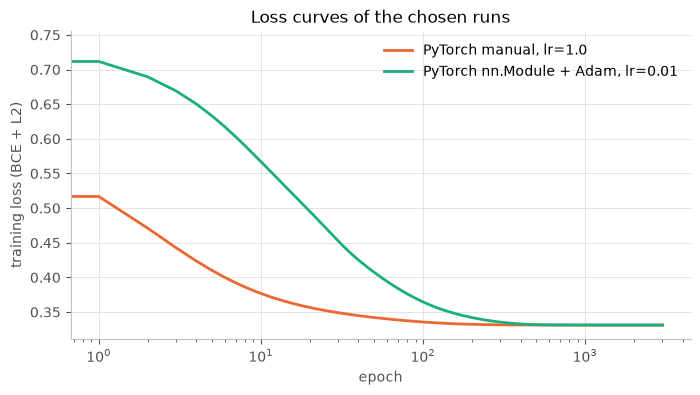

In [19]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(history_manual, color="#eb6834", lw=2, label=f"PyTorch manual, lr={BEST_LR_MANUAL}")
ax.plot(history_standard, color="#1baf7a", lw=2, label=f"PyTorch nn.Module + Adam, lr={BEST_LR_STANDARD}")
ax.set(xlabel="epoch", ylabel="training loss (BCE + L2)", xscale="log",
       title="Loss curves of the chosen runs")
ax.legend()
show()

### 6.5 Do the three agree?

Validation metrics, coefficients, and the largest gaps from scikit-learn. PyTorch
computes in 32-bit floats and scikit-learn in 64-bit, so gaps around 0.001 or below are
rounding and convergence tolerance, not a real disagreement. (Fed 32-bit inputs,
scikit-learn's own fit is not exactly reproducible: the experience and age bands
overlap, which leaves some coefficients in a very flat part of the loss.)

In [20]:
comparison = pd.DataFrame({name: evaluate(y_val, p) for name, p in val_probs.items()}).T
print(comparison.round(4))

coefficients = pd.DataFrame(
    {
        "scikit-learn": np.r_[sk_model.intercept_, sk_model.coef_[0]],
        "PyTorch manual": np.r_[b_manual.numpy(), w_manual.numpy()],
        "PyTorch nn.Module": np.r_[torch_model.linear.bias.detach().numpy(),
                                   torch_model.linear.weight.detach().numpy()[0]],
    },
    index=["(intercept)"] + prep.feature_names_,
)
gaps = coefficients.drop(columns="scikit-learn").sub(coefficients["scikit-learn"], axis=0).abs()
print("\nlargest coefficient gap from scikit-learn:")
print(gaps.max().round(5).to_string())
print("\nlargest validation-probability gap from scikit-learn:")
for name in ["PyTorch manual", "PyTorch nn.Module"]:
    print(f"  {name}: {np.abs(val_probs[name] - val_probs['scikit-learn']).max():.5f}")
coefficients.round(3)

                   log loss   Brier  ROC-AUC
naive baseline       0.6219  0.2152   0.5000
scikit-learn         0.3409  0.1080   0.9143
PyTorch manual       0.3409  0.1080   0.9143
PyTorch nn.Module    0.3409  0.1080   0.9143

largest coefficient gap from scikit-learn:
PyTorch manual       0.00047
PyTorch nn.Module    0.00001

largest validation-probability gap from scikit-learn:
  PyTorch manual: 0.00002
  PyTorch nn.Module: 0.00000


,scikit-learn,PyTorch manual,PyTorch nn.Module
(intercept),-1.674,-1.674,-1.674
AGE=26-39,-0.029,-0.029,-0.029
AGE=40-64,-0.034,-0.034,-0.034
AGE=65+,-0.000,-0.000,-0.000
DRIVING_EXPERIENCE=10-19y,-1.026,-1.026,-1.026
DRIVING_EXPERIENCE=20-29y,-1.831,-1.831,-1.831
DRIVING_EXPERIENCE=30y+,-1.769,-1.769,-1.769
EDUCATION=high school,-0.041,-0.041,-0.041
EDUCATION=university,-0.020,-0.020,-0.020
INCOME=working class,0.052,0.052,0.052


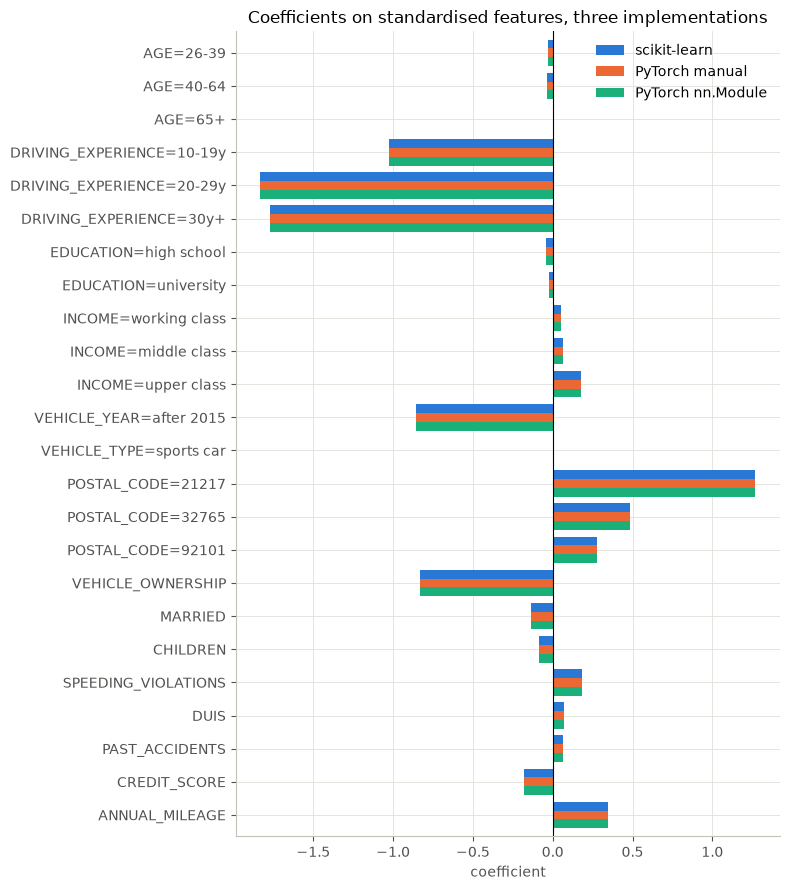

In [21]:
ax = coefficients.drop(index="(intercept)").plot.barh(figsize=(8, 9), width=0.8)
ax.axvline(0, color="k", lw=0.8)
ax.invert_yaxis()
ax.set(title="Coefficients on standardised features, three implementations",
       xlabel="coefficient")
plt.tight_layout()
show()

### 6.6 What breaks the agreement

Two deliberate mismatches, to show which choices the agreement depends on:

1. **No L2 term in PyTorch.** Postal code 21217 has only claimers in the training set,
   so without a penalty its coefficient keeps growing the longer training runs.
2. **Learning rate too small.** Same objective, but training stops before reaching the
   minimum.

In [22]:
i_21217 = prep.feature_names_.index("POSTAL_CODE=21217")
w_sk = torch.tensor(sk_model.coef_[0], dtype=torch.float32)

runs = {
    f"scikit-learn, C={BEST_C}": (w_sk, None),
    f"manual, no L2, {EPOCHS} epochs": train_manual(X_train_t, y_train_t, BEST_LR_MANUAL, lam=0.0)[:2],
    f"manual, no L2, {3 * EPOCHS} epochs":
        train_manual(X_train_t, y_train_t, BEST_LR_MANUAL, lam=0.0, epochs=3 * EPOCHS)[:2],
    "manual, lr=0.01 (too small)": train_manual(X_train_t, y_train_t, 0.01)[:2],
}
rows = []
for name, (w, b) in runs.items():
    row = {"run": name, "21217 coefficient": w[i_21217].item(),
           "largest gap from sklearn": (w - w_sk).abs().max().item()}
    if b is not None:
        row["validation log loss"] = log_loss(y_val, predict_manual(w, b, X_val_t))
    rows.append(row)
pd.DataFrame(rows).set_index("run").round(4)

,21217 coefficient,largest gap from sklearn,validation log loss
run,,,
"scikit-learn, C=1.0",1.2689,0.0000,NaN
"manual, no L2, 3000 epochs",1.4650,0.1961,0.3410
"manual, no L2, 9000 epochs",1.5922,0.3234,0.3410
"manual, lr=0.01 (too small)",0.6227,1.2890,0.3573


## 7. Threshold, calibration and the test set (Legal version)

### 7.1 Are the probabilities calibrated?

The cost-based threshold t* from section 3 is only the best choice if a predicted 30%
really means that about 30% of such applicants claim. Same checks as the calibration
lab, on the validation set: reliability diagram, expected calibration error (ECE), and
expected vs. actual number of claims.

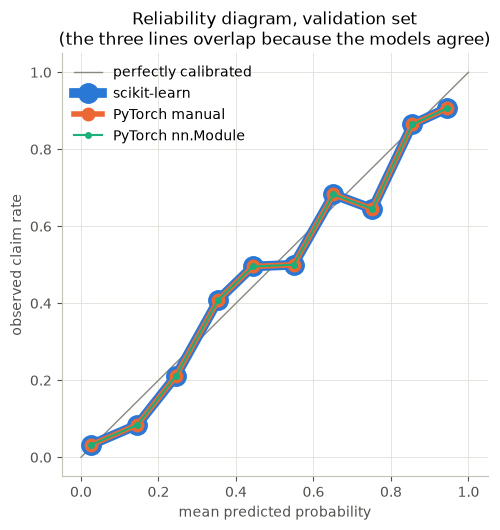

,ECE,expected claims (sum of p),actual claims
model,,,
scikit-learn,0.03,645.606,627
PyTorch manual,0.03,645.606,627
PyTorch nn.Module,0.03,645.606,627


In [23]:
from sklearn.calibration import calibration_curve

IMPLEMENTATIONS = ["scikit-learn", "PyTorch manual", "PyTorch nn.Module"]
COLORS = dict(zip(IMPLEMENTATIONS, ["#2a78d6", "#eb6834", "#1baf7a"]))
# The three agree, so their curves land on the same points: draw them from thickest to
# thinnest so all three stay visible (stacked lines, nested markers)
LINE_WIDTH = dict(zip(IMPLEMENTATIONS, [7, 4, 1.5]))
MARKER_SIZE = dict(zip(IMPLEMENTATIONS, [14, 9, 4]))


def expected_calibration_error(y, p, n_bins=10):
    """Same definition as the calibration lab: weighted |observed - predicted| per bin."""
    bins = np.minimum((p * n_bins).astype(int), n_bins - 1)
    return sum((bins == k).mean() * abs(y[bins == k].mean() - p[bins == k].mean())
               for k in range(n_bins) if (bins == k).any())


fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], color="#898781", lw=1, label="perfectly calibrated")
rows = []
for name in IMPLEMENTATIONS:
    p = val_probs[name]
    observed, predicted = calibration_curve(y_val, p, n_bins=10)
    ax.plot(predicted, observed, "o-", lw=LINE_WIDTH[name], ms=MARKER_SIZE[name],
            color=COLORS[name], label=name)
    rows.append({"model": name, "ECE": expected_calibration_error(y_val, p),
                 "expected claims (sum of p)": p.sum(), "actual claims": int(y_val.sum())})
ax.set(xlabel="mean predicted probability", ylabel="observed claim rate",
       title="Reliability diagram, validation set\n(the three lines overlap because the models agree)")
ax.legend()
show()
pd.DataFrame(rows).set_index("model").round(3)

### 7.2 Choosing the threshold

t* comes from the costs alone (section 3). To check it, every threshold from 0 to 1 is
tried on the validation set and the profit per applicant is computed. The threshold
used from here on is t*: it depends only on the costs, so it cannot overfit the
validation set, and the sweep checks that it is close to the best one.

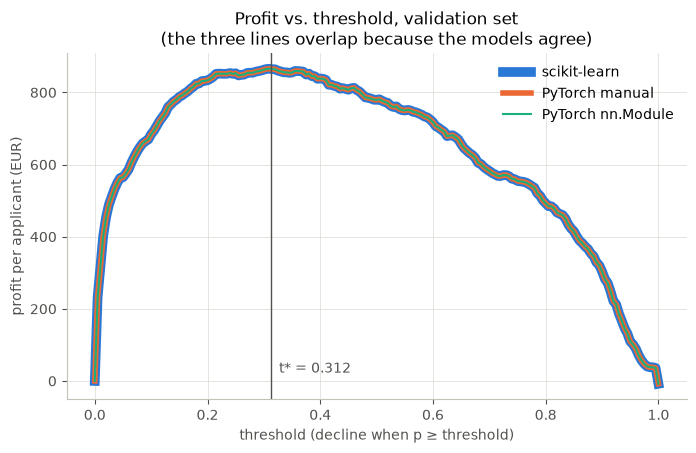

profit per applicant at t* = 0.312:         EUR     867
best threshold on the sweep (0.310):     EUR     866
accept everyone:                          EUR      -8
decline everyone:                         EUR       0


In [24]:
VALUES = {"TP": V_TP, "FP": V_FP, "FN": V_FN, "TN": V_TN}
thresholds = np.linspace(0, 1, 201)

fig, ax = plt.subplots(figsize=(8, 4.5))
for name in IMPLEMENTATIONS:
    curve = [profit_per_applicant(y_val, val_probs[name], t, VALUES) for t in thresholds]
    ax.plot(thresholds, curve, lw=LINE_WIDTH[name], color=COLORS[name], label=name)
ax.axvline(T_STAR, color="#52514e", lw=1)
ax.annotate(f"t* = {T_STAR:.3f}", (T_STAR, 0), xytext=(6, 6), textcoords="offset points",
            color="#52514e")
ax.set(xlabel="threshold (decline when p ≥ threshold)", ylabel="profit per applicant (EUR)",
       title="Profit vs. threshold, validation set\n(the three lines overlap because the models agree)")
ax.legend()
show()

p_val = val_probs["scikit-learn"]
sweep = np.array([profit_per_applicant(y_val, p_val, t, VALUES) for t in thresholds])
THRESHOLD = T_STAR
print(f"profit per applicant at t* = {T_STAR:.3f}:         EUR {profit_per_applicant(y_val, p_val, T_STAR, VALUES):7,.0f}")
print(f"best threshold on the sweep ({thresholds[sweep.argmax()]:.3f}):     EUR {sweep.max():7,.0f}")
print(f"accept everyone:                          EUR {profit_per_applicant(y_val, np.zeros_like(p_val), T_STAR, VALUES):7,.0f}")
print(f"decline everyone:                         EUR {profit_per_applicant(y_val, np.ones_like(p_val), T_STAR, VALUES):7,.0f}")

### 7.3 Test set (used once)

Final numbers for the Legal model, compared with the naive baseline, with two policies
that need no model (accept everyone, decline everyone), and with perfect foresight
(decline exactly the applicants who will claim).

In [25]:
test_probs = {
    "naive baseline": np.full(len(y_test), train_claim_rate),
    "scikit-learn": sk_model.predict_proba(X_test)[:, 1],
    "PyTorch manual": predict_manual(w_manual, b_manual, X_test_t),
    "PyTorch nn.Module": predict_standard(torch_model, X_test_t),
}

rows = []
for name, p in test_probs.items():
    declined = p >= THRESHOLD
    rows.append({"model": name, **evaluate(y_test, p),
                 "accuracy at t*": (declined == y_test).mean(),
                 "share declined": declined.mean(),
                 "profit per applicant (EUR)": profit_per_applicant(y_test, p, THRESHOLD, VALUES),
                 "expected claims (sum of p)": p.sum()})
test_results = pd.DataFrame(rows).set_index("model")

print(f"actual claims in the test set: {int(y_test.sum())} of {len(y_test)}")
print(f"naive baseline gives everyone p = {train_claim_rate:.4f}; t* = {T_STAR:.4f}, so it "
      f"{'declines' if train_claim_rate >= T_STAR else 'accepts'} everyone")
policies = {"accept everyone": np.zeros(len(y_test)), "decline everyone": np.ones(len(y_test)),
            "perfect foresight": y_test}
for name, decision in policies.items():
    print(f"{name:18s} EUR {profit_per_applicant(y_test, decision, THRESHOLD, VALUES):7,.0f} per applicant")
test_results.round(3)

actual claims in the test set: 626 of 2000
naive baseline gives everyone p = 0.3133; t* = 0.3122, so it declines everyone
accept everyone    EUR      -5 per applicant
decline everyone   EUR       0 per applicant
perfect foresight  EUR   1,243 per applicant


,log loss,Brier,ROC-AUC,accuracy at t*,share declined,profit per applicant (EUR),expected claims (sum of p)
model,,,,,,,
naive baseline,0.621,0.215,0.500,0.313,1.000,0.000,626.667
scikit-learn,0.351,0.112,0.909,0.822,0.412,832.761,634.798
PyTorch manual,0.351,0.112,0.909,0.822,0.412,832.761,634.798
PyTorch nn.Module,0.351,0.112,0.909,0.822,0.412,832.761,634.798


In [26]:
from sklearn.metrics import confusion_matrix

for name in ["PyTorch manual", "PyTorch nn.Module"]:
    different = ((test_probs[name] >= THRESHOLD) != (test_probs["scikit-learn"] >= THRESHOLD)).sum()
    print(f"{name}: {different} test applicants get a different decision than with scikit-learn")

# Rows: what happened. Columns: what the model decided at t*.
pd.DataFrame(confusion_matrix(y_test, test_probs["scikit-learn"] >= THRESHOLD),
             index=["no claim (0)", "claim (1)"], columns=["accepted", "declined"])

PyTorch manual: 0 test applicants get a different decision than with scikit-learn
PyTorch nn.Module: 0 test applicants get a different decision than with scikit-learn


,accepted,declined
no claim (0),1097,277
claim (1),80,546


## 8. Legal vs. illegal models

**The business question.** What would the insurer gain if it could use the banned
columns, and does the ban change who gets declined?

| Version | Columns | Status |
|---|---|---|
| **Full** | everything, including gender and race | Illegal in the EU: race everywhere, gender since the Test-Achats ruling (Case C-236/09, applied from 21 December 2012) |
| **Legal** | everything except gender and race | The main model of sections 5–7 |
| **Strict** | Legal minus postal code and credit score | Legal, but drops the two columns most often criticised as stand-ins for protected attributes |

Each version goes through the same pipeline: its own `Preprocessor` fitted on the
training set, C chosen on validation log loss, trained three ways with the learning
rates from section 6, and evaluated on the test set at the same t* (the costs do not
change).

In [27]:
C_GRID = [0.001, 0.01, 0.1, 1, 10, 100]


def fit_version(name):
    prep_v = Preprocessor(FEATURE_SETS[name]).fit(train_df)
    X = {split: prep_v.transform(part)
         for split, part in [("train", train_df), ("val", val_df), ("test", test_df)]}
    X_t = {split: torch.tensor(array, dtype=torch.float32) for split, array in X.items()}

    # Regularisation chosen on validation log loss, as in section 6.2
    val_loss = {C: log_loss(y_val, LogisticRegression(C=C, max_iter=5000)
                            .fit(X["train"], y_train).predict_proba(X["val"])[:, 1])
                for C in C_GRID}
    C = min(val_loss, key=val_loss.get)
    lam = 1.0 / (C * len(y_train))

    sk = LogisticRegression(C=C, max_iter=5000, tol=1e-8).fit(X["train"], y_train)
    w, b, history_m = train_manual(X_t["train"], y_train_t, BEST_LR_MANUAL, lam=lam)
    net, history_s = train_standard(X_t["train"], y_train_t, BEST_LR_STANDARD, lam=lam)
    return {
        "prep": prep_v, "C": C, "sklearn": sk, "manual": (w, b), "standard": net,
        "histories": {"PyTorch manual": history_m, "PyTorch nn.Module": history_s},
        "test_probs": {"scikit-learn": sk.predict_proba(X["test"])[:, 1],
                       "PyTorch manual": predict_manual(w, b, X_t["test"]),
                       "PyTorch nn.Module": predict_standard(net, X_t["test"])},
    }


versions = {name: fit_version(name) for name in ["full", "legal", "strict"]}
assert np.allclose(versions["legal"]["test_probs"]["scikit-learn"], test_probs["scikit-learn"])

rows = []
for name, v in versions.items():
    p = v["test_probs"]["scikit-learn"]
    rows.append({
        "version": name, "features": len(v["prep"].feature_names_), "C": v["C"],
        **evaluate(y_test, p),
        "share declined": (p >= THRESHOLD).mean(),
        "profit per applicant (EUR)": profit_per_applicant(y_test, p, THRESHOLD, VALUES),
        "largest gap between implementations": max(
            np.abs(v["test_probs"][impl] - p).max() for impl in IMPLEMENTATIONS[1:]),
    })
version_results = pd.DataFrame(rows).set_index("version")
version_results.round(4)

,features,C,log loss,Brier,ROC-AUC,share declined,profit per applicant (EUR),largest gap between implementations
version,,,,,,,,
full,26,100,0.3341,0.1055,0.9188,0.4025,863.5294,0.0017
legal,24,1,0.3508,0.1120,0.9091,0.4115,832.7615,0.0000
strict,20,10,0.3913,0.1240,0.8841,0.3920,781.1108,0.0000


### 8.1 What the ban costs

The profit difference between two versions on the same test applicants, with a 95%
bootstrap interval (the test set is resampled 2,000 times) to show whether the
difference is larger than the noise from having only 2,000 test applicants.

In [28]:
rng = np.random.default_rng(SEED)
resamples = rng.integers(0, len(y_test), size=(2000, len(y_test)))

per_applicant = {name: outcome_values(y_test, v["test_probs"]["scikit-learn"], THRESHOLD, VALUES)
                 for name, v in versions.items()}

gains = []
for better, worse, label in [("full", "legal", "adding gender and race"),
                             ("legal", "strict", "keeping postal code and credit score")]:
    diff = per_applicant[better] - per_applicant[worse]
    low, high = np.percentile(diff[resamples].mean(axis=1), [2.5, 97.5])
    gains.append({"comparison": f"{better} vs. {worse}", "gain from": label,
                  "per applicant (EUR)": diff.mean(), "95% low": low, "95% high": high})
    print(f"gain from {label} ({better} - {worse}): EUR {diff.mean():6.1f} per applicant "
          f"(95% interval {low:6.1f} to {high:6.1f}), EUR {diff.mean() * 10_000:,.0f} per 10,000 applicants")

gain from adding gender and race (full - legal): EUR   30.8 per applicant (95% interval    3.4 to   57.0), EUR 307,680 per 10,000 applicants
gain from keeping postal code and credit score (legal - strict): EUR   51.7 per applicant (95% interval   23.0 to   78.5), EUR 516,507 per 10,000 applicants


### 8.2 Who gets declined

Share of each group declined at t*, by version, next to the group's actual claim rate
on the test set.

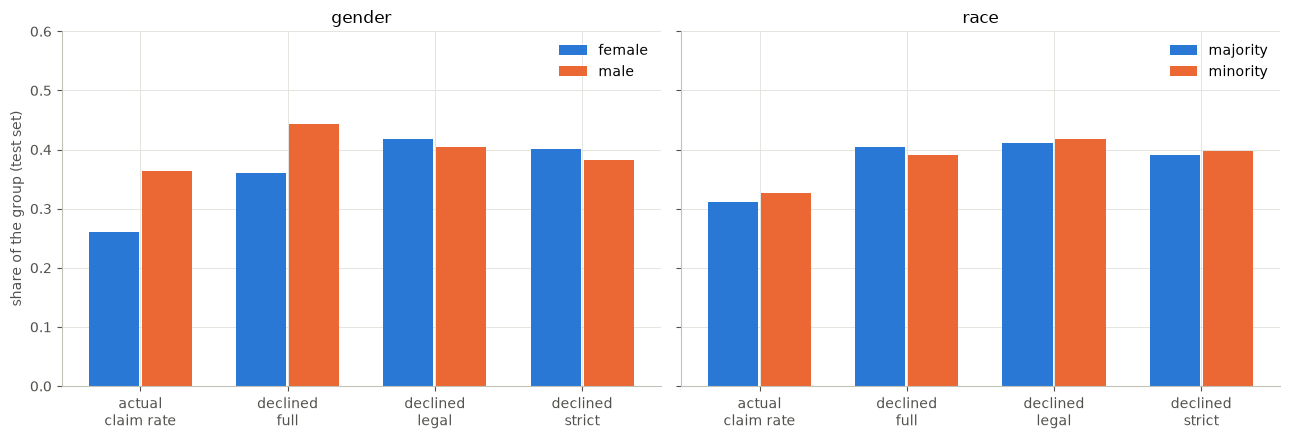

applicants  actual claim rate  declined (full)  declined (legal)  declined (strict)
attribute group                                                                                        
GENDER    female           984              0.260            0.360             0.419              0.401
          male            1016              0.364            0.444             0.405              0.383
RACE      majority        1816              0.312            0.404             0.411              0.392
          minority         184              0.326            0.391             0.418              0.397

In [29]:
rows = []
for attr in ["GENDER", "RACE"]:
    for group in CATEGORIES[attr]:
        mask = (test_df[attr] == group).to_numpy()
        row = {"attribute": attr, "group": group, "applicants": int(mask.sum()),
               "actual claim rate": y_test[mask].mean()}
        for name, v in versions.items():
            row[f"declined ({name})"] = (v["test_probs"]["scikit-learn"][mask] >= THRESHOLD).mean()
        rows.append(row)
group_rates = pd.DataFrame(rows).set_index(["attribute", "group"])

columns = ["actual claim rate", "declined (full)", "declined (legal)", "declined (strict)"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, attr in zip(axes, ["GENDER", "RACE"]):
    table = group_rates.loc[attr, columns]
    x = np.arange(len(columns))
    for i, group in enumerate(table.index):
        ax.bar(x + (i - 0.5) * 0.36, table.loc[group], width=0.34, label=group)
    ax.set_xticks(x, ["actual\nclaim rate", "declined\nfull", "declined\nlegal", "declined\nstrict"])
    ax.set(title=attr.lower(), ylim=(0, 0.6))
    ax.legend()
axes[0].set_ylabel("share of the group (test set)")
fig.tight_layout()
show()
group_rates.round(3)

### 8.3 Can the legal columns stand in for the banned ones?

A logistic regression is trained to predict gender, and race, from each version's
columns. ROC-AUC on the test set: 0.5 means the columns say nothing about the banned
attribute, 1.0 means it can be fully recovered.

In [30]:
rows = []
for attr, positive in [("GENDER", "male"), ("RACE", "minority")]:
    target_train = (train_df[attr] == positive).to_numpy()
    target_test = (test_df[attr] == positive).to_numpy()
    for name in ["legal", "strict"]:
        prep_v = versions[name]["prep"]
        clf = LogisticRegression(max_iter=5000).fit(prep_v.transform(train_df), target_train)
        auc = roc_auc_score(target_test, clf.predict_proba(prep_v.transform(test_df))[:, 1])
        rows.append({"banned attribute": attr, "predicted from": name, "ROC-AUC": auc})
proxy_auc = pd.DataFrame(rows).pivot(index="banned attribute", columns="predicted from", values="ROC-AUC")
proxy_auc.round(3)

predicted from,legal,strict
banned attribute,,
GENDER,0.727,0.710
RACE,0.558,0.563


## 9. Saved artifacts for the app

The app never trains anything. Everything it needs is saved to `artifacts/`:

- per version (`full/`, `legal/`, `strict/`): the fitted `Preprocessor`, the
  scikit-learn model, the manual weights `w` and `b`, and the `nn.Module` state dict;
- `split.csv`: which split each `ID` belongs to, so the app can show the training data
  and score the test set with the saved models;
- `meta.json`: costs, threshold, chosen hyperparameters, the loss curves, and the
  results of sections 8.1 and 8.3 (they involve resampling or fitting, which the app
  must not repeat).

In [31]:
import json

import joblib

ARTIFACTS = Path("artifacts")
for name, v in versions.items():
    folder = ARTIFACTS / name
    folder.mkdir(parents=True, exist_ok=True)
    joblib.dump(v["prep"], folder / "preprocessor.joblib")
    joblib.dump(v["sklearn"], folder / "sklearn.joblib")
    w, b = v["manual"]
    torch.save({"w": w, "b": b}, folder / "manual.pt")
    torch.save(v["standard"].state_dict(), folder / "standard.pt")

pd.concat([pd.DataFrame({"ID": part["ID"], "split": split})
           for split, part in [("train", train_df), ("validation", val_df), ("test", test_df)]]
          ).to_csv(ARTIFACTS / "split.csv", index=False)

meta = {
    "costs": {"avg_claim_cost": AVG_CLAIM_COST, "expense_ratio": EXPENSE_RATIO,
              "target_loss_ratio": TARGET_LOSS_RATIO, "standard_premium": STANDARD_PREMIUM,
              "values": VALUES},
    "threshold": T_STAR,
    "train_claim_rate": train_claim_rate,
    "C": {name: v["C"] for name, v in versions.items()},
    "learning_rates": {"PyTorch manual": BEST_LR_MANUAL, "PyTorch nn.Module": BEST_LR_STANDARD},
    "epochs": EPOCHS,
    "loss_histories": {name: v["histories"] for name, v in versions.items()},
    "gains": gains,                        # section 8.1 (the bootstrap is not repeated in the app)
    "proxy_auc": proxy_auc.to_dict(),      # section 8.3 (needs a fitted model, so it is saved here)
}
(ARTIFACTS / "meta.json").write_text(json.dumps(meta))

for path in sorted(ARTIFACTS.rglob("*")):
    if path.is_file():
        print(f"{str(path):40s} {path.stat().st_size / 1024:8.1f} KB")

artifacts/full/manual.pt                      1.8 KB
artifacts/full/preprocessor.joblib            4.8 KB
artifacts/full/sklearn.joblib                 1.0 KB
artifacts/full/standard.pt                    2.0 KB
artifacts/legal/manual.pt                     1.8 KB
artifacts/legal/preprocessor.joblib           4.7 KB
artifacts/legal/sklearn.joblib                1.0 KB
artifacts/legal/standard.pt                   2.0 KB
artifacts/meta.json                         359.2 KB
artifacts/split.csv                         133.6 KB
artifacts/strict/manual.pt                    1.8 KB
artifacts/strict/preprocessor.joblib          4.2 KB
artifacts/strict/sklearn.joblib               1.0 KB
artifacts/strict/standard.pt                  2.0 KB
